In [3]:
import functools
import numpy as np
import qiskit as qk
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from scipy.optimize import curve_fit
import qutip as qt
from tqdm import tqdm

import sys

sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Full calibration and benchmarking of robust gateset

First, we activate the IBM service we are going to be using.

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService, Session, SamplerV2 as Sampler

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
service = QiskitRuntimeService(token=IBM_TOKEN, channel="ibm_quantum")

And we get backend information.

In [5]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = service.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 225 # dt
desired_duration = 120  # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints["granularity"]

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

Then we load our robust gateset.

In [6]:
# pico_a = ps.from_csv(
#     "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
# )
# pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2"], pico_a)}
pico_a = ps.from_csv(
    "../pico-pulses/saved-pulses-2024-04-16/a_single_qubit_gateset_R1e-3.csv"
)
pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2", "i1"], pico_a)}

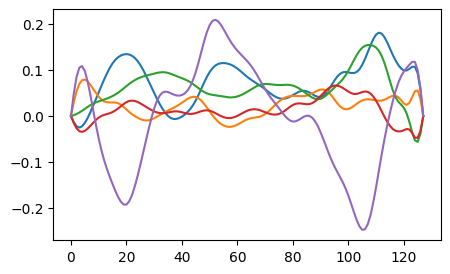

In [7]:
fig, ax = plt.subplots(figsize=[5, 3])
for row in pico_a:
    ax.plot(row)

And we define a Guassian gateset to which we are going to compare.

In [8]:
default_gates = {
    "x1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "x2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 2),
    "sx1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
    "sx2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi / 4),
    "i1": ps.zero_envelope(duration),
}

The maximum aplitude allowed by qiskit pulse is the `amp` factor times the amplitude of the signal we are sending.

In [9]:
signal = pico_gates["x1"]
x1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

signal = pico_gates["sx1"]
sx1_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

print(x1_max, sx1_max)
print(1 / x1_max, 1 / sx1_max)

0.1934816204784005 0.1650713414525134
5.168449579486729 6.057986754094885


In [10]:
signal = pico_gates["x2"]
x2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

signal = pico_gates["sx2"]
sx2_max = np.max(np.abs(ps.resample(duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt)))))

print(x2_max, sx2_max)
print(1 / x2_max, 1 / sx2_max)

0.08379813487336044 0.07089857655785758
11.933439825495467 14.104655531186


## Rough amplitude calibration

We choose two qubits with good T1/T2 times and a range of amplitudes to calibrate the gates.

In [11]:
qubit0, qubit1 = 0, 1
qubit2, qubit3 = 2, 3
qubit4, qubit5 = 4, 5

In [165]:
drive_amps_1 = np.linspace(-3.6, 3.6, 50)
drive_amps_2 = np.linspace(-8.7, 8.7, 50)

And we create schedules with our robust gates using this range of amplitudes.

In [166]:
def get_schedules(signal, qubit: int, drive_amps: list[float]):
    schedules = []
    for amp in drive_amps:
        with qk.pulse.build(name=f"rabi_sched", backend=backend) as sched:
            signal_samples = ps.resample(
                duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
            )
            gate = ps.scalable_symbolic_pulse(
                duration, signal_samples, "custom", amp=amp
            )
            qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
        schedules.append(sched)
    return schedules

In [167]:
robust_x1_schedules = get_schedules(pico_gates["x1"], qubit0, drive_amps_1)

We do the same for the Gaussian pulses.

In [168]:
gaussian_x1_schedules = get_schedules(default_gates["x1"].samples, qubit0, drive_amps_1)

We can use the schedules to create circuits that we can run to IBM.

In [169]:
num_qubits = backend.num_qubits
num_qubits

127

In [170]:
def get_circuits_from_scheds(schedules, num_qubits: int, qubit: int):
    circuits = []
    for i, schedule in enumerate(schedules):
        gate = qk.circuit.Gate(f"x_rabi", 1, [])
        cr = qk.ClassicalRegister(1, name="c")
        qr = qk.QuantumRegister(num_qubits, name="q")
        qc = qk.QuantumCircuit(qr, cr, name=f"schedule")
        qc.append(gate, [qubit])
        qc.measure(qubit, cr[0])
        qc.add_calibration(gate, (qubit,), schedule)
        circuits.append(qc)
    return circuits

In [171]:
robust_x1_circuits = get_circuits_from_scheds(robust_x1_schedules, num_qubits, qubit0)
robust_x1_circuits[0].draw(idle_wires=False)

┌────────┐┌─┐
q_0: ┤ x_rabi ├┤M├
     └────────┘└╥┘
c: 1/═══════════╩═
                0

We can parallelize our calibration by running circuits that act on different qubits at the same time. So, we can calibrate both x gates in parallel, and both sx gates in parallel. We can also do more qubit pairs.

In [172]:
def construct_parallel_circuits(qubits: list[int], signals, drive_amps_list: list[list[float]], num_qubits: int):
    assert len(qubits) == len(signals)

    qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(len(drive_amps_list[0]))]
    crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(len(drive_amps_list[0]))]
    qcs = [qk.QuantumCircuit(qrs[i], crs[i]) for i in range(len(drive_amps_list[0]))]

    for i, (qubit, signal) in enumerate(zip(qubits, signals)):
        schedules = get_schedules(signal, qubit, drive_amps_list[i])
        circuits = get_circuits_from_scheds(schedules, num_qubits, qubit)
        
        for j, (qc, circuit) in enumerate(zip(qcs, circuits)):
            qc.append(circuit, qargs=qrs[j], cargs=(crs[j][i],))

            # have to add calibrations to new circuit
            gate = qk.circuit.Gate("x_rabi", 1, [])
            qc.add_calibration(gate, (qubit,), schedules[j])

    return [qc.decompose() for qc in qcs]

In [173]:
qubits = [qubit0, qubit1, qubit2, qubit3, qubit4, qubit5]
x_signals = [pico_gates["x1"], pico_gates["x2"]] * 3
sx_signals = [pico_gates["sx1"], pico_gates["sx2"]] * 3
drive_amps_list = [drive_amps_1, drive_amps_2] * 3

x_parallel_circuits = construct_parallel_circuits(qubits, x_signals, drive_amps_list, num_qubits)
sx_parallel_circuits = construct_parallel_circuits(qubits, sx_signals, drive_amps_list, num_qubits)

In [174]:
x_parallel_circuits[3].draw(idle_wires=False)

┌────────┐┌─┐               
q_0: ┤ x_rabi ├┤M├───────────────
     ├────────┤└╥┘┌─┐            
q_1: ┤ x_rabi ├─╫─┤M├────────────
     ├────────┤ ║ └╥┘┌─┐         
q_2: ┤ x_rabi ├─╫──╫─┤M├─────────
     ├────────┤ ║  ║ └╥┘┌─┐      
q_3: ┤ x_rabi ├─╫──╫──╫─┤M├──────
     ├────────┤ ║  ║  ║ └╥┘┌─┐   
q_4: ┤ x_rabi ├─╫──╫──╫──╫─┤M├───
     ├────────┤ ║  ║  ║  ║ └╥┘┌─┐
q_5: ┤ x_rabi ├─╫──╫──╫──╫──╫─┤M├
     └────────┘ ║  ║  ║  ║  ║ └╥┘
c: 6/═══════════╩══╩══╩══╩══╩══╩═
                0  1  2  3  4  5

So, as you can see above, we parallelize the rough calibration by running circuits of the form above (we omit idle wires in the drawing to save space).

We can now run the calibration jobs. But first, we have to open a runtime session and save its id.

In [175]:
session = Session(backend=backend)
print(f"Session id: {session.session_id}")

Session id: cs16tbskfpw00080cyy0


In [176]:
sampler = Sampler(backend=backend, session=session)
sampler.options.experimental = {"execution": {"fast_parametric_update": False}} # make sure pulse instructions are sent correctly

In [177]:
num_shots_per_point = 1024

In [178]:
x_parallel_jobs = sampler.run(x_parallel_circuits, shots=num_shots_per_point)

In [182]:
x_parallel_jobs.job_id()

'cs16tf1bqt7g0081w11g'

In [185]:
x_parallel_jobs.status()

<JobStatus.DONE: 'job has successfully run'>

In [184]:
x_parallel_jobs = service.job("cs16tf1bqt7g0081w11g")

We define the functions that will help us analyze the calibration data.

In [186]:
def get_qubit_one_counts(counts, qubit, num_qubits):
    total = 0
    for key, val in counts.items():
        if key[num_qubits - qubit - 1] == "1": # because of little-endian
            total += val
    return total

In [187]:
def get_rabi_values(job, shots, qubits):
    rabi_values = [[] for _ in range(len(qubits))] # each list element is the data for a single qubit
    result = job.result()
    for i in range(len(result)):
        counts = result[i].data.c.get_counts()
        for j in range(len(qubits)):
            rabi_values[j].append(get_qubit_one_counts(counts, j, len(qubits)) / shots)
    return rabi_values

In [188]:
x_rabi_values = get_rabi_values(x_parallel_jobs, num_shots_per_point, qubits)

In [189]:
def fit_function(x_values, y_values, function, init_params):
    fitparams, conv = curve_fit(function, x_values, y_values, init_params)
    y_fit = function(x_values, *fitparams)
    return fitparams, y_fit, conv

def baseline_remove(values):
    return np.array(values) - np.mean(values)

In [246]:
def get_drive_period(
    rabi_values: list[float], 
    drive_amps: list[float], 
    factor: int,
    gate_name: str = "",
    plot: bool = False, 
    qubit: int = 0,
    amplitude_max: float = 1,
    normal_params: bool = True,
):
    """factor is 2 for x gates and 4 for sx gates"""
    rabi_values = np.real(baseline_remove(rabi_values))
    
    starting_params = [1, 1.5, 2.5, 0.5] if normal_params else [1, 1.5, 6, 0.5]
    fit_params, y_fit, _ = fit_function(
        drive_amps,
        rabi_values,
        lambda x, A, B, drive_period, phi: (
            A * np.cos(2 * np.pi * x / drive_period - phi) + B
        ),
        starting_params,
    )

    drive_period = fit_params[2]  # get period of rabi oscillation
    
    if plot:
        plot_amps = amplitude_max * np.array(drive_amps)
        plt.scatter(plot_amps, rabi_values, marker="x", color="black")
        plt.plot(plot_amps, y_fit)

        plt.xlabel("Maximum pulse amplitude")
        plt.ylabel("Prob. of meas. 1 (baseline removed)")
        plt.title(f"{gate_name} calibration on qubit {qubit}")
        plt.show()

    return drive_period / factor

And we get the estimated amplitudes.

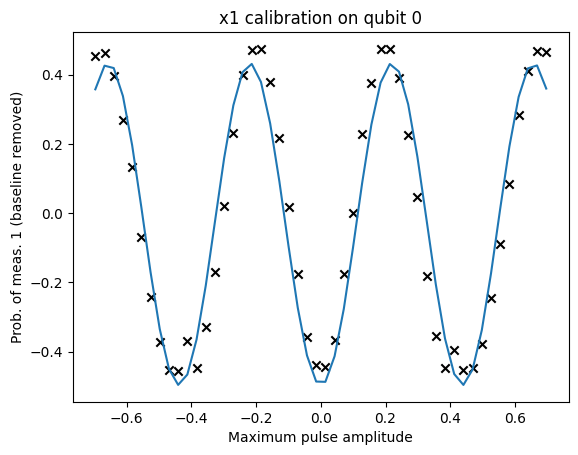

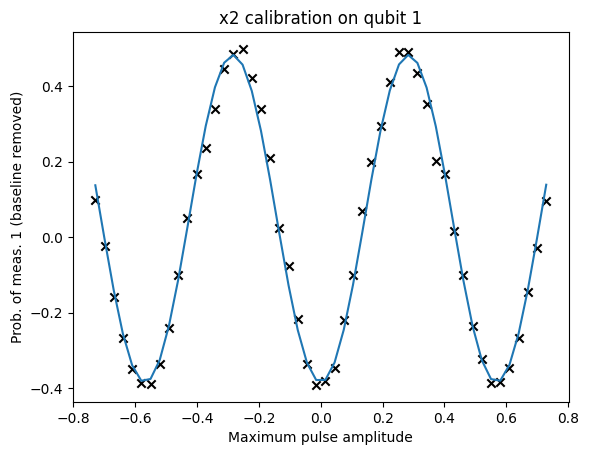

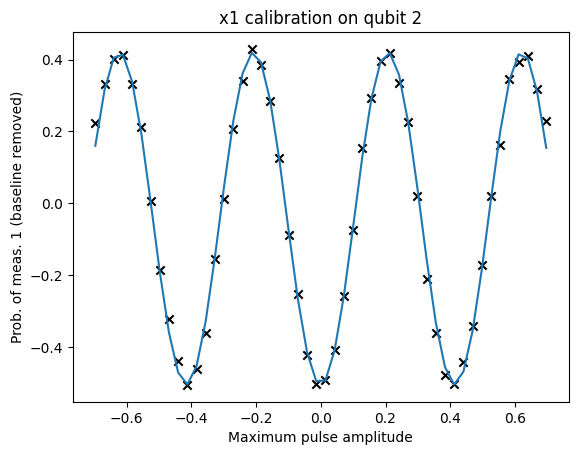

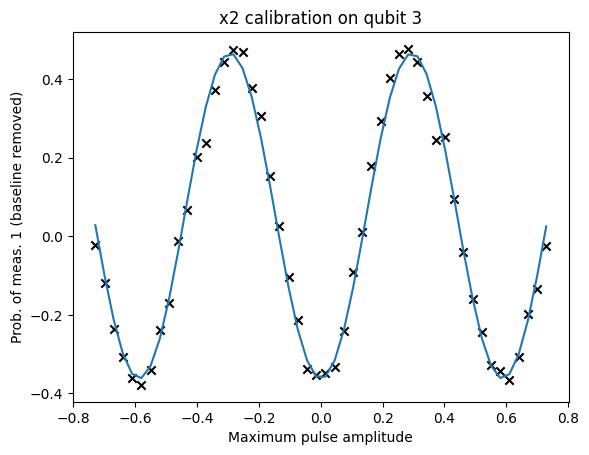

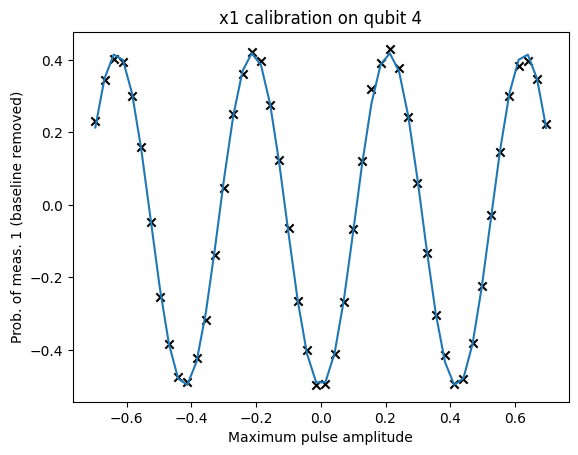

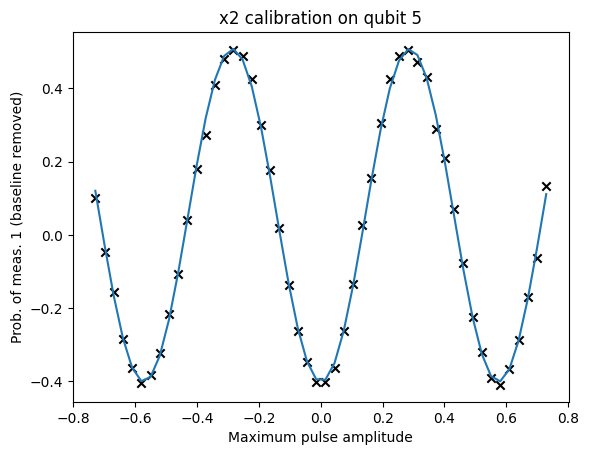

In [247]:
x_rough_amps = []
for i, (qubit, rabi) in enumerate(zip(qubits, x_rabi_values)):
    x_rough_amps.append(get_drive_period(
        rabi,
        drive_amps_list[i],
        2,
        gate_name=f"x{i % 2 + 1}",
        plot=True, 
        qubit=qubit, 
        amplitude_max= x1_max if i % 2 == 0 else x2_max,
        normal_params=True if i % 2 == 0 else False,  
    ))

In [248]:
for i, (qubit, period) in enumerate(zip(qubits, x_rough_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate period: {period}")

Qubit 0 x1 gate period: 1.1314539394936953
Qubit 1 x2 gate period: 3.3909033302128635
Qubit 2 x1 gate period: 1.0720076912643672
Qubit 3 x2 gate period: 3.5071311482699326
Qubit 4 x1 gate period: 1.0862346763532795
Qubit 5 x2 gate period: 3.4201103248058176


In [249]:
sx_rough_amps = [] 
for i in range(len(x_rough_amps)):
    if i % 2 == 0:
        sx_rough_amps.append(x_rough_amps[i] * 0.6)
    else:
        sx_rough_amps.append(x_rough_amps[i])

## Fine amplitude calibration

We can then use the amplitudes from the rough calibration and further calibrate them using the fine calibration protocol.

In [250]:
def build_schedule(signal, qubit: int, amp: float):
    with qk.pulse.build(backend=backend) as sched:
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
        )
        gate = ps.scalable_symbolic_pulse(
            duration, signal_samples, "custom", amp=amp
        )
        qk.pulse.play(gate.get_waveform(), qk.pulse.DriveChannel(qubit))
    return sched

In [251]:
def get_fine_experiment(sched, qubit: int, gate: str, backend, x_gate: bool = True):
    inst_map = qk.pulse.InstructionScheduleMap()
    inst_map.add(gate, (qubit,), sched)
    if x_gate:
        exp = qk_e.library.FineXAmplitude((qubit,), backend)
    else:
        exp = qk_e.library.FineSXAmplitude((qubit,), backend)
    exp.set_transpile_options(inst_map=inst_map)
    return exp

We know construct the fine amplitude experiments.

In [252]:
fine_x_experiments = []
fine_sx_experiments = []

for i, (qubit, signal) in enumerate(zip(qubits, x_signals)):
    sched = build_schedule(signal, qubit, x_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "x", backend, x_gate=True)
    fine_x_experiments.append(exp)

for i, (qubit, signal) in enumerate(zip(qubits, sx_signals)):
    sched = build_schedule(signal, qubit, sx_rough_amps[i])
    exp = get_fine_experiment(sched, qubit, "sx", backend, x_gate=False)
    fine_sx_experiments.append(exp)

And parallelize them like we did with the rough calibration circuits.

In [253]:
x_num_circuits = len(fine_x_experiments[0].circuits())
x_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(x_num_circuits)]
x_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(x_num_circuits)]
fine_x_circuits = [qk.QuantumCircuit(x_qrs[i], x_crs[i]) for i in range(x_num_circuits)]

sx_num_circuits = len(fine_sx_experiments[0].circuits())
sx_qrs = [qk.QuantumRegister(num_qubits, "q") for _ in range(sx_num_circuits)]
sx_crs = [qk.ClassicalRegister(len(qubits), "c") for _ in range(sx_num_circuits)]
fine_sx_circuits = [qk.QuantumCircuit(sx_qrs[i], sx_crs[i]) for i in range(sx_num_circuits)]

for i, qubit in enumerate(qubits):
    x_circuits = fine_x_experiments[i].circuits()
    sx_circuits = fine_sx_experiments[i].circuits()

    x_schedule = build_schedule(x_signals[i], qubit, x_rough_amps[i])
    sx_schedule = build_schedule(sx_signals[i], qubit, sx_rough_amps[i])

    for j in range(x_num_circuits):
        fine_x_circuits[j].append(x_circuits[j], qargs=(x_qrs[j][qubit],), cargs=(x_crs[j][i],))
        gate = qk.circuit.library.XGate()
        fine_x_circuits[j].add_calibration(gate, (qubit,), x_schedule)
        
    for j in range(sx_num_circuits):
        fine_sx_circuits[j].append(sx_circuits[j], qargs=(sx_qrs[j][qubit],), cargs=(sx_crs[j][i],))
        gate = qk.circuit.library.SXGate()
        fine_sx_circuits[j].add_calibration(gate, (qubit,), sx_schedule)

fine_x_circuits = [circuit.decompose() for circuit in fine_x_circuits]
fine_sx_circuits = [circuit.decompose() for circuit in fine_sx_circuits]

In [254]:
fine_x_circuits[3].draw(idle_wires=False)

┌────┐┌───┐┌───┐┌─┐               
q_0: ┤ √X ├┤ X ├┤ X ├┤M├───────────────
     ├────┤├───┤├───┤└╥┘┌─┐            
q_1: ┤ √X ├┤ X ├┤ X ├─╫─┤M├────────────
     ├────┤├───┤├───┤ ║ └╥┘┌─┐         
q_2: ┤ √X ├┤ X ├┤ X ├─╫──╫─┤M├─────────
     ├────┤├───┤├───┤ ║  ║ └╥┘┌─┐      
q_3: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫─┤M├──────
     ├────┤├───┤├───┤ ║  ║  ║ └╥┘┌─┐   
q_4: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫──╫─┤M├───
     ├────┤├───┤├───┤ ║  ║  ║  ║ └╥┘┌─┐
q_5: ┤ √X ├┤ X ├┤ X ├─╫──╫──╫──╫──╫─┤M├
     └────┘└───┘└───┘ ║  ║  ║  ║  ║ └╥┘
c: 6/═════════════════╩══╩══╩══╩══╩══╩═
                      0  1  2  3  4  5

In [255]:
fine_x_circuits[3].calibrations["x"][((1,), ())] # we can check calibrations were added 

ScheduleBlock(Play(Waveform(array([ 0.05957432+0.j,  0.16222818+0.j,  0.23511658+0.j,  0.27521817+0.j,
        0.28651428+0.j,  0.27481353+0.j,  0.24810375+0.j,  0.21451806+0.j,
        0.18051212+0.j,  0.15073774+0.j,  0.12807513+0.j,  0.11418749+0.j,
        0.10834273+0.j,  0.10738332+0.j,  0.10755811+0.j,  0.10436929+0.j,
        0.09457656+0.j,  0.07823228+0.j,  0.05771286+0.j,  0.03668011+0.j,
        0.01773824+0.j,  0.00129574+0.j, -0.01265711+0.j, -0.02377949+0.j,
       -0.03124208+0.j, -0.0339591 +0.j, -0.03135586+0.j, -0.02360104+0.j,
       -0.01192297+0.j,  0.00179629+0.j,  0.01561555+0.j,  0.02853123+0.j,
        0.04045877+0.j,  0.05177062+0.j,  0.06311109+0.j,  0.07541519+0.j,
        0.08962042+0.j,  0.10556666+0.j,  0.12199228+0.j,  0.13687452+0.j,
        0.14780329+0.j,  0.15200663+0.j,  0.14730904+0.j,  0.13318792+0.j,
        0.1104237 +0.j,  0.08134297+0.j,  0.04889948+0.j,  0.01655325+0.j,
       -0.01294922+0.j, -0.03817727+0.j, -0.05817553+0.j, -0.07257138+0.

And we submit this parallel jobs.

In [256]:
num_shots = 4000 # number extracted from non-parallelized experiments

In [ ]:
x_fine_jobs = sampler.run(fine_x_circuits, shots=num_shots)
sx_fine_jobs = sampler.run(fine_sx_circuits, shots=num_shots)

In [259]:
x_fine_jobs.job_id(), sx_fine_jobs.job_id()

('cs1793w75q40008tmja0', 'cs1794cyhpyg008agw0g')

In [265]:
x_fine_jobs.status(), sx_fine_jobs.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [261]:
x_fine_jobs = service.job("cs1793w75q40008tmja0")
sx_fine_jobs = service.job("cs1794cyhpyg008agw0g")

To get the experiment results, we have to extract the individual counts for each qubit and experiment, and then put it back together in a way that the experiment framework is able to process it. This is quite complicated and done in the next few cells.

In [266]:
def get_qubit_counts(counts, qubit, num_qubits):
    qubit_counts = {}
    for key, val in counts.items():
        if key[num_qubits - qubit - 1] in qubit_counts:
            qubit_counts[key[num_qubits - qubit - 1]] += val
        else:
            qubit_counts[key[num_qubits - qubit - 1]] = val
    return qubit_counts    

In [267]:
fine_x_metadata = []
for i in range(x_num_circuits):
    fine_x_metadata.append(fine_x_experiments[0].circuits()[i].metadata)

fine_sx_metadata = []
for i in range(sx_num_circuits):
    fine_sx_metadata.append(fine_sx_experiments[0].circuits()[i].metadata)

In [268]:
def reconstruct_data(experiments, job, qubits: list[int], shots: int, metadata: list[dict[str, any]]):
    exp_datas = []
    num_qubits = len(qubits)
    results = job.result()

    for experiment, qubit in zip(experiments, qubits):
        exp_data = qk_e.framework.ExperimentData(experiment=experiment)
    
        experiment_results = []
        for result, meta in zip(results, metadata):
            counts = get_qubit_counts(result.data.c.get_counts(), qubit, num_qubits)
            experiment_result_data = qk.result.models.ExperimentResultData(counts=counts)
            header = qk.qobj.QobjExperimentHeader(metadata=meta)
            experiment_result = qk.result.models.ExperimentResult(
                shots=shots,
                success=True,
                data=experiment_result_data,
                meas_level=2,
                header=header,
            )
            experiment_results.append(experiment_result)

        result = qk.result.Result(
            backend_name=backend.name, 
            backend_version=backend.configuration().backend_version,
            qobj_id="Unknown",
            job_id="Unknown",
            success=True,
            results=experiment_results,
        )
        exp_data.add_data(result)
        experiment.analysis.run(exp_data, replace_results=True)
        exp_datas.append(exp_data)
    
    return exp_datas

In [269]:
fine_x_exp_datas = reconstruct_data(
    experiments=fine_x_experiments,
    job=x_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_x_metadata,
)

fine_sx_exp_datas = reconstruct_data(
    experiments=fine_sx_experiments,
    job=sx_fine_jobs,
    qubits=qubits,
    shots=num_shots,
    metadata=fine_sx_metadata,
)

In [270]:
def get_fine_amplitude_estimation(data, target_angle: float):
    dtheta = data.analysis_results("d_theta").value.nominal_value
    return target_angle / (target_angle + dtheta)

In [271]:
x_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 2) for data in fine_x_exp_datas]
x_fine_amps = [x_rough_amps[i] * ratio for i, ratio in enumerate(x_fine_ratios)]

sx_fine_ratios = [get_fine_amplitude_estimation(data, np.pi / 4) for data in fine_sx_exp_datas]
sx_fine_amps = [sx_rough_amps[i] * ratio for i, ratio in enumerate(sx_fine_ratios)]

Qubit 0 pulse x1


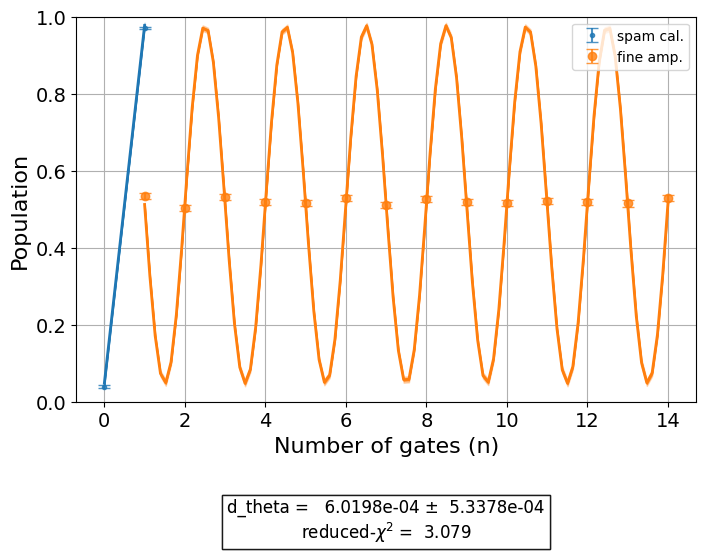

In [272]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 1 pulse x2


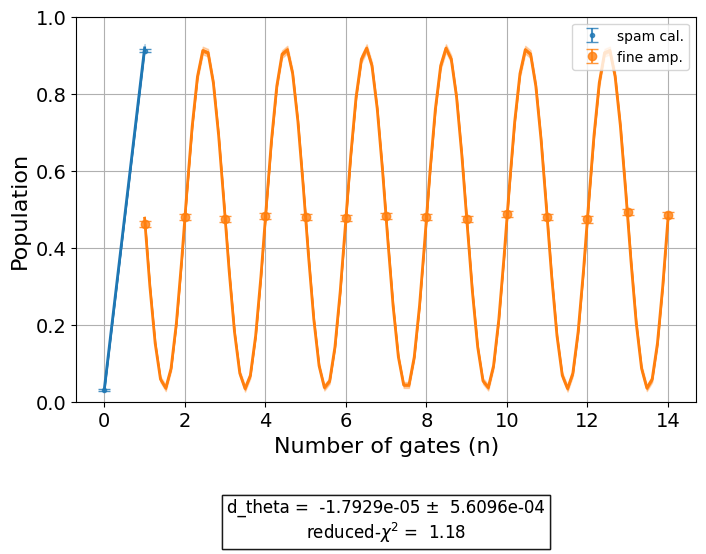

In [273]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 3 pulse x2


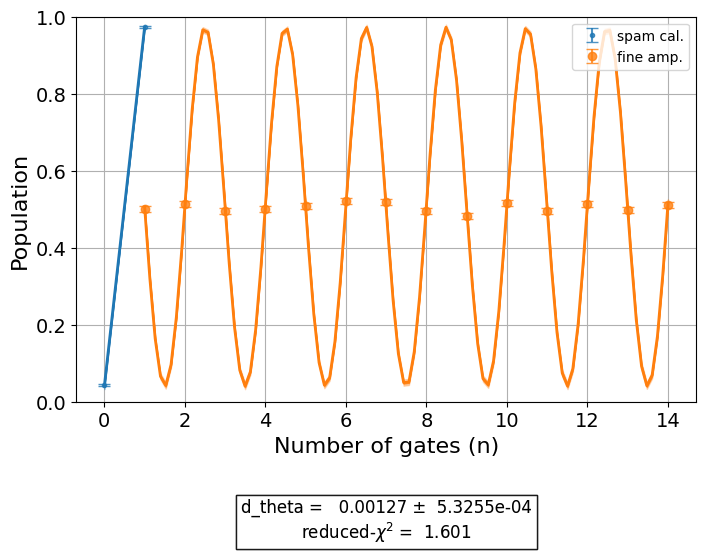

In [274]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 4 pulse x1


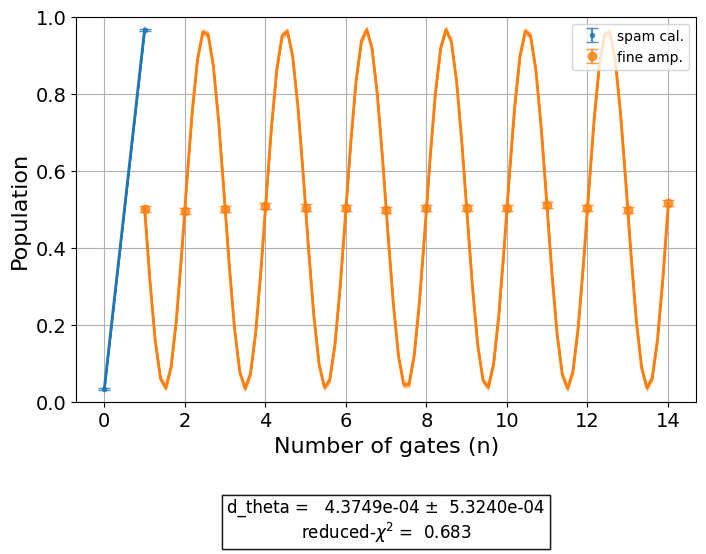

In [275]:
qubit_index = 4
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 5 pulse x2


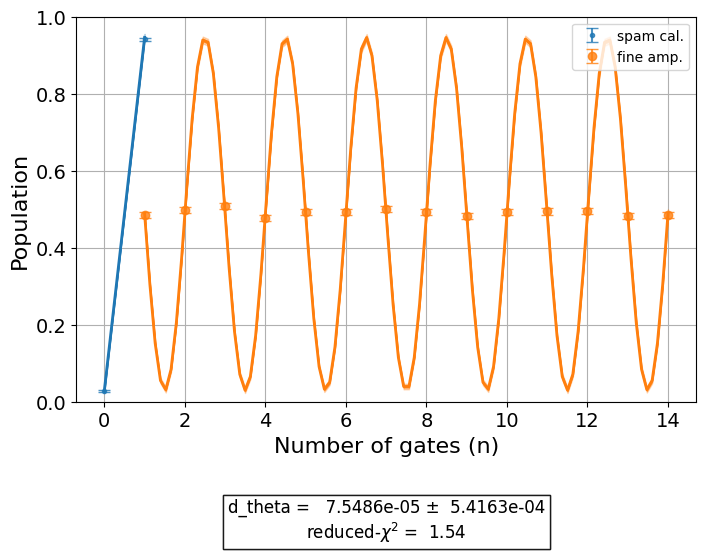

In [276]:
qubit_index = 5
print(f"Qubit {qubits[qubit_index]} pulse x{qubit_index % 2 + 1}")
fine_x_exp_datas[qubit_index].figure(0)

Qubit 0 pulse sx1


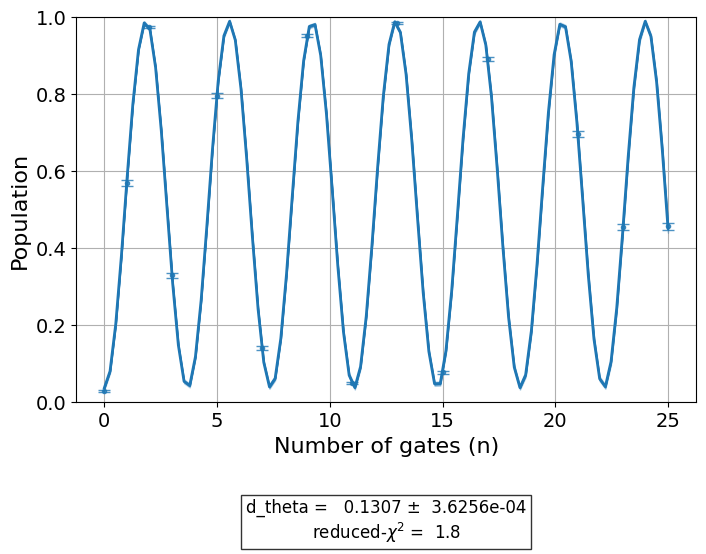

In [277]:
qubit_index = 0
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 1 pulse sx2


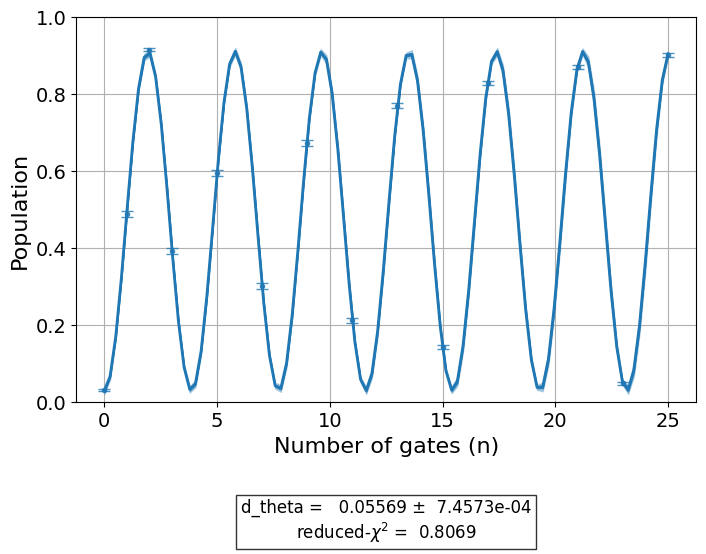

In [278]:
qubit_index = 1
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 2 pulse sx1


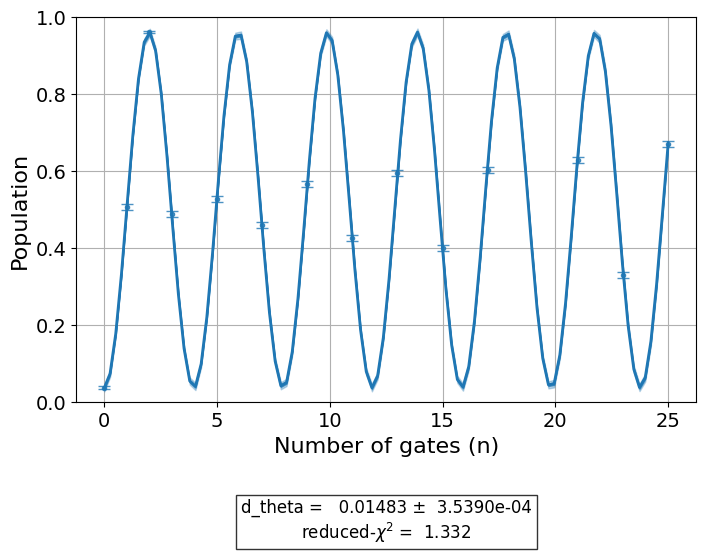

In [279]:
qubit_index = 2
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 3 pulse sx2


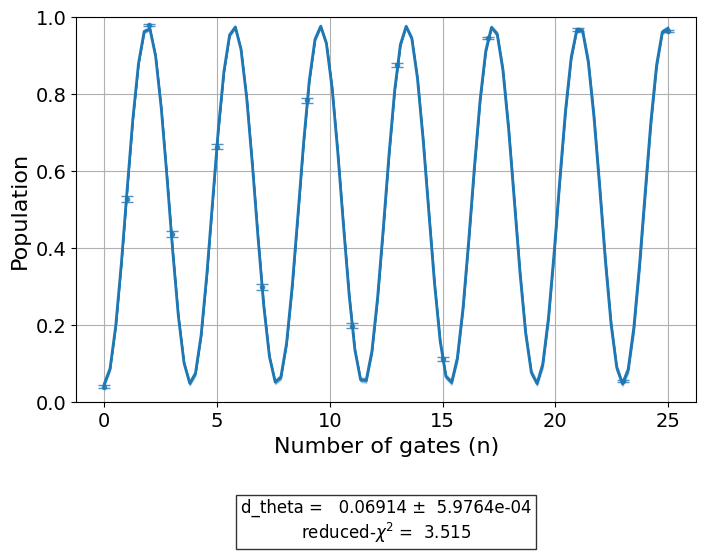

In [280]:
qubit_index = 3
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 4 pulse sx1


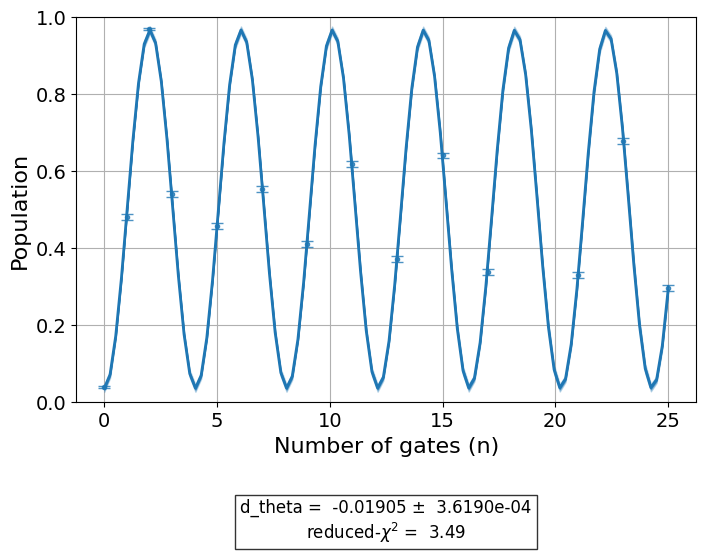

In [281]:
qubit_index = 4
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

Qubit 5 pulse sx2


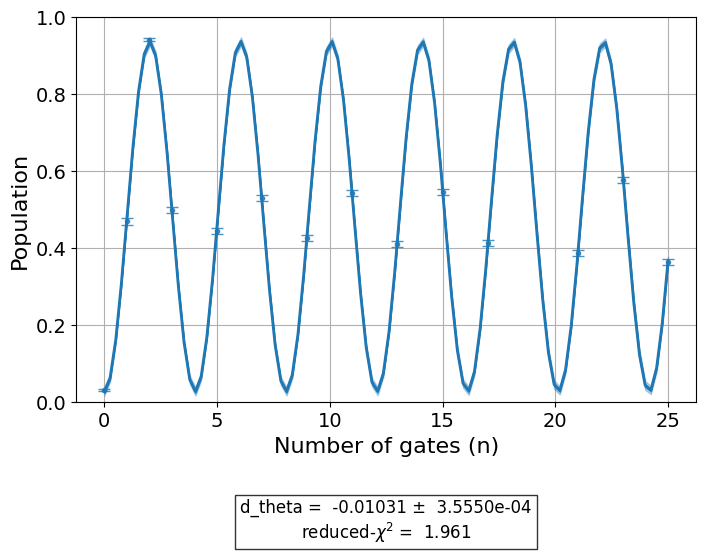

In [282]:
qubit_index = 5
print(f"Qubit {qubits[qubit_index]} pulse sx{qubit_index % 2 + 1}")
fine_sx_exp_datas[qubit_index].figure(0)

We can check the amplitude ratios again after the fine calibration.

In [283]:
for i, (qubit, amp) in enumerate(zip(qubits, x_fine_amps)):
    print(f"Qubit {qubit} x{i % 2 + 1} gate amplitude: {amp}")

Qubit 0 x1 gate amplitude: 1.1310204985247518
Qubit 1 x2 gate amplitude: 3.3909420349196098
Qubit 2 x1 gate amplitude: 1.0721670238326535
Qubit 3 x2 gate amplitude: 3.5042987818664963
Qubit 4 x1 gate amplitude: 1.085932228625261
Qubit 5 x2 gate amplitude: 3.419945976197246


In [284]:
for i, (qubit, amp) in enumerate(zip(qubits, sx_fine_amps)):
    print(f"Qubit {qubit} sx{i % 2 + 1} gate amplitude: {amp}")

Qubit 0 sx1 gate amplitude: 0.5819974858673483
Qubit 1 sx2 gate amplitude: 3.166400944615359
Qubit 2 sx1 gate amplitude: 0.6312858137351836
Qubit 3 sx2 gate amplitude: 3.2233791031613883
Qubit 4 sx1 gate amplitude: 0.6679427990635654
Qubit 5 sx2 gate amplitude: 3.465616107854782


In [285]:
for i, (x_amp, sx_amp) in enumerate(zip(x_fine_amps, sx_fine_amps)):
    print(f"Ratio of sx{i % 2 + 1} to x{i % 2 + 1} on qubit {qubits[i]}:", sx_amp / x_amp)

Ratio of sx1 to x1 on qubit 0: 0.514577310160583
Ratio of sx2 to x2 on qubit 1: 0.9337820912324813
Ratio of sx1 to x1 on qubit 2: 0.5887942827028377
Ratio of sx2 to x2 on qubit 3: 0.9198356943309834
Ratio of sx1 to x1 on qubit 4: 0.615087002168772
Ratio of sx2 to x2 on qubit 5: 1.0133540506123193


## XYXY Sequences

In [286]:
fine_q0_x1 = build_schedule(pico_gates["x1"], qubits[0], x_fine_amps[0])
fine_q1_x2 = build_schedule(pico_gates["x2"], qubits[1], x_fine_amps[1])
fine_q0_sx1 = build_schedule(pico_gates["sx1"], qubits[0], sx_fine_amps[0])
fine_q1_sx2 = build_schedule(pico_gates["sx2"], qubits[1], sx_fine_amps[1])

In [287]:
def xyxy_sequence(n: int, q0: int, q1: int, schedules = None):
    qc = qk.QuantumCircuit(2)
    qc.sx(0)
    qc.sx(1)
    for _ in range(n):
        qc.x(0)
        qc.y(0)
        qc.x(0)
        qc.y(0)
        qc.x(1)
        qc.y(1)
        qc.x(1)
        qc.y(1)
    qc.sx(0)
    qc.sx(1)
    qc.measure_all()

    if schedules is not None:
        x_gate = qk.circuit.library.XGate()
        qc.add_calibration(x_gate, (q0,), schedules[0])
        qc.add_calibration(x_gate, (q1,), schedules[1])
        sx_gate = qk.circuit.library.SXGate()
        qc.add_calibration(sx_gate, (q0,), schedules[2])
        qc.add_calibration(sx_gate, (q1,), schedules[3])

    return qk.transpile(qc, basis_gates=["x", "sx", "rz", "id"], optimization_level=0)

In [288]:
example = xyxy_sequence(1, qubits[0], qubits[1], [fine_q0_x1, fine_q1_x2, fine_q0_sx1, fine_q1_sx2])
example.draw()

┌────┐┌───┐┌───────┐┌───┐┌───┐┌───────┐┌───┐┌────┐ ░ ┌─┐   
   q_0: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├─░─┤M├───
        ├────┤├───┤├───────┤├───┤├───┤├───────┤├───┤├────┤ ░ └╥┘┌─┐
   q_1: ┤ √X ├┤ X ├┤ Rz(π) ├┤ X ├┤ X ├┤ Rz(π) ├┤ X ├┤ √X ├─░──╫─┤M├
        └────┘└───┘└───────┘└───┘└───┘└───────┘└───┘└────┘ ░  ║ └╥┘
meas: 2/══════════════════════════════════════════════════════╩══╩═
                                                              0  1

In [289]:
lengths = list(range(1, 51, 1))
dd_circuits_robust = [xyxy_sequence(i, qubits[0], qubits[1], [fine_q0_x1, fine_q1_x2, fine_q0_sx1, fine_q1_sx2]) for i in lengths]
dd_circuits_default = [xyxy_sequence(i, qubits[0], qubits[1]) for i in lengths]

In [290]:
dd_jobs_robust = sampler.run(dd_circuits_robust, shots=2048)
dd_jobs_default = sampler.run(dd_circuits_default, shots=2048)

In [291]:
dd_jobs_robust.job_id(), dd_jobs_default.job_id()

('cs17a0ryhpyg008agw50', 'cs17a10965y000850jkg')

In [297]:
dd_jobs_robust.status(), dd_jobs_default.status()

(<JobStatus.DONE: 'job has successfully run'>,
 <JobStatus.DONE: 'job has successfully run'>)

In [293]:
dd_jobs_robust = service.job("cs17a0ryhpyg008agw50")
dd_jobs_default = service.job("cs17a10965y000850jkg")

In [298]:
robust_results = dd_jobs_robust.result()
robust_counts = []
for result in robust_results:
    robust_counts.append(result.data.meas.get_counts())

default_results = dd_jobs_default.result()
default_counts = []
for result in default_results:
    default_counts.append(result.data.meas.get_counts())

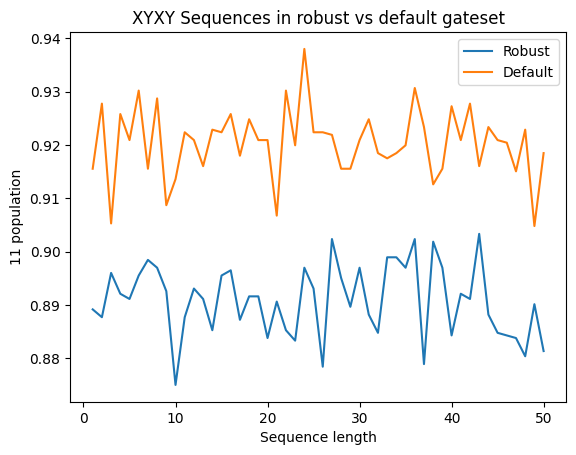

In [299]:
robust_11 = [count.get("11", 0) / 2048 for count in robust_counts]
default_11 = [count.get("11", 0) / 2048 for count in default_counts]

plt.plot(lengths, robust_11, label="Robust")
plt.plot(lengths, default_11, label="Default")
plt.xlabel("Sequence length")
plt.ylabel("11 population")
plt.title("XYXY Sequences in robust vs default gateset")
plt.legend()
plt.show()

In [300]:
session.cancel()
session.close()
session.status()

'Closed'